<a href="https://colab.research.google.com/github/silviacatellani05-hash/DAT105-Gallstone/blob/main/Gallestone_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Can machine learning models provide reliable gallstone probabilities for new patients, and which features drive these probabilities?**

Setup the jupyter notebook and unzip the folders downloaded from: https://archive.ics.uci.edu/dataset/1150/gallstone-1
expects a zip file named 'gallstone-1.zip'

In [1]:
!unzip -o gallstone-1.zip
!unzip -o dataset-uci.zip
!ls
!ls -l dataset-uci.xlsx
!pip install python-calamine

Archive:  gallstone-1.zip
  inflating: dataset-uci.zip         
Archive:  dataset-uci.zip
  inflating: dataset-uci.xlsx        
dataset-uci.xlsx  dataset-uci.zip  gallstone-1.zip  sample_data
-rw-rw-rw- 1 root root 78082 Apr 20  2025 dataset-uci.xlsx
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.1/953.1 kB 17.6 MB/s  0:00:00


Extract the data and invest on it:

In [2]:
import pandas as pd
df = pd.read_excel("dataset-uci.xlsx", engine="calamine")
a=df.shape
print(f'shape of the data = {a}')
b= df.duplicated().sum()
print(f'number of duplicates = {b}')

shape of the data = (319, 39)
number of duplicates = 0


Investigate on the target variable "Gallstone Status" with Gallstones present(0) and absent(1)

In [3]:
df["Gallstone Status"].value_counts()


,count
Gallstone Status,
0,161
1,158


Some investigation on the patients itself

Gender:

In [4]:
y = df["Gender"].replace({0: "Male", 1: "Female"})
print(y.value_counts().to_string())


Gender
Male      162
Female    157


Age distribution:

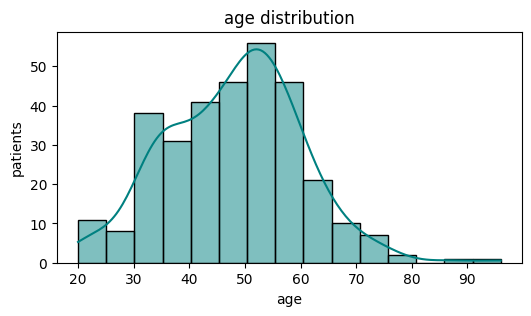

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (6,3))

sns.histplot(data=df, x='Age', kde=True, color='teal')

plt.title('age distribution')
plt.xlabel('age')
plt.ylabel('patients');

**Train different models**

Now we implement our first model (logistic regression) as an example for a linear model:

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Split by table: without the target column and the target column only
X,Y = df.drop(columns=["Gallstone Status"]), df["Gallstone Status"]

# define the model (logistic regression)
# StandardScalar to normalize all values since they are of different size
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# split the dataset into 5 Sets with seed 10 to make the diffent models comparable
# StratifiedKFold keeps track that there are round about the same number of patients with
# gallstone disease in each set
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

# Perform 5-fold cross-validation to train and evaluate the model
# In each fold, the model is trained on 4 subsets and tested on the remaining subset
# ROC-AUC is used to measure the model's ability to distinguish between the two classes
result = cross_val_score(model, X, Y, cv=cross_validation, scoring="roc_auc")

# print the 5 different probabilites and calculate the mean
print(result, result.mean())

# Fit model on the complete dataset
model.fit(X, Y)

# Extract logistic regression coefficients
coefficients = model.named_steps["logisticregression"].coef_[0]

# Calculate feature importance using absolute coefficients
feature_importance = pd.Series(abs(coefficients), index=X.columns)

# Sort and print the 5 most important features
print("\nTop 5 Most Important Clinical Features:")
print(feature_importance.sort_values(ascending=False).head(5))


[0.82209189 0.87207031 0.88964844 0.87011719 0.8921371 ] 0.869212984176442

Top 5 Most Important Clinical Features:
C-Reactive Protein (CRP)     1.637480
Bone Mass (BM)               1.442332
Intracellular Water (ICW)    1.108890
Gender                       0.987120
Vitamin D                    0.887132
dtype: float64


Second model: Random Forest (model working with trees)

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=10)

result_rf = cross_val_score(rf, X, Y, cv=cross_validation, scoring="roc_auc")
print(result_rf, result_rf.mean())

rf.fit(X, Y)

feature_importance_rf = pd.Series(rf.feature_importances_,index=X.columns)

print("\nTop 5 Most Important Clinical Features (Random Forest):")
print(feature_importance_rf.sort_values(ascending=False).head(5))

[0.83186706 0.84082031 0.90869141 0.85742188 0.81804435] 0.8513690012524439

Top 5 Most Important Clinical Features (Random Forest):
C-Reactive Protein (CRP)                          0.160085
Vitamin D                                         0.080721
Extracellular Fluid/Total Body Water (ECF/TBW)    0.043418
Aspartat Aminotransferaz (AST)                    0.042361
Extracellular Water (ECW)                         0.034795
dtype: float64


Third model: Boosting Algorithm (trees, but learns at each round)

In [12]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
    subsample=0.8, eval_metric="logloss", random_state=10,)

result_xgbclassifier = cross_val_score(xgb, X, Y, cv=cross_validation, scoring="roc_auc")
print(result_xgbclassifier, result_xgbclassifier.mean())

xgb.fit(X, Y)

feature_importance_xgb = pd.Series(xgb.feature_importances_,index=X.columns)

print("\nTop 5 Most Important Clinical Features:")
print(feature_importance_xgb.sort_values(ascending=False).head(5))

[0.82404692 0.82226562 0.90332031 0.88964844 0.84979839] 0.8578159365835777

Top 5 Most Important Clinical Features:
C-Reactive Protein (CRP)                          0.110887
Vitamin D                                         0.048217
Lean Mass (LM) (%)                                0.046339
Extracellular Fluid/Total Body Water (ECF/TBW)    0.040996
Aspartat Aminotransferaz (AST)                    0.038055
dtype: float32


Fourth model: k-Nearest Neighbors (distance-based model)

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))

result_knn = cross_val_score(knn, X, Y, cv=cross_validation, scoring="roc_auc")
print(result_knn, result_knn.mean())

knn.fit(X, Y)

perm_importance = permutation_importance(knn, X, Y, scoring="roc_auc", n_repeats=10,
    random_state=10)

feature_importance_knn = pd.Series(perm_importance.importances_mean,
    index=X.columns)

# Sort and print the 5 most important features
print("\nTop 5 Most Important Clinical Features (KNN):")
print(feature_importance_knn.sort_values(ascending=False).head(5))

[0.69990225 0.70214844 0.79541016 0.69775391 0.77620968] 0.7342848851417398

Top 5 Most Important Clinical Features (KNN):
Extracellular Fluid/Total Body Water (ECF/TBW)    0.033189
Vitamin D                                         0.033106
C-Reactive Protein (CRP)                          0.020273
Hyperlipidemia                                    0.017093
Bone Mass (BM)                                    0.008741
dtype: float64


blaYou can see that CRP and Vit D is a very important feature in the models. Thats why we plot it in a boxplot.

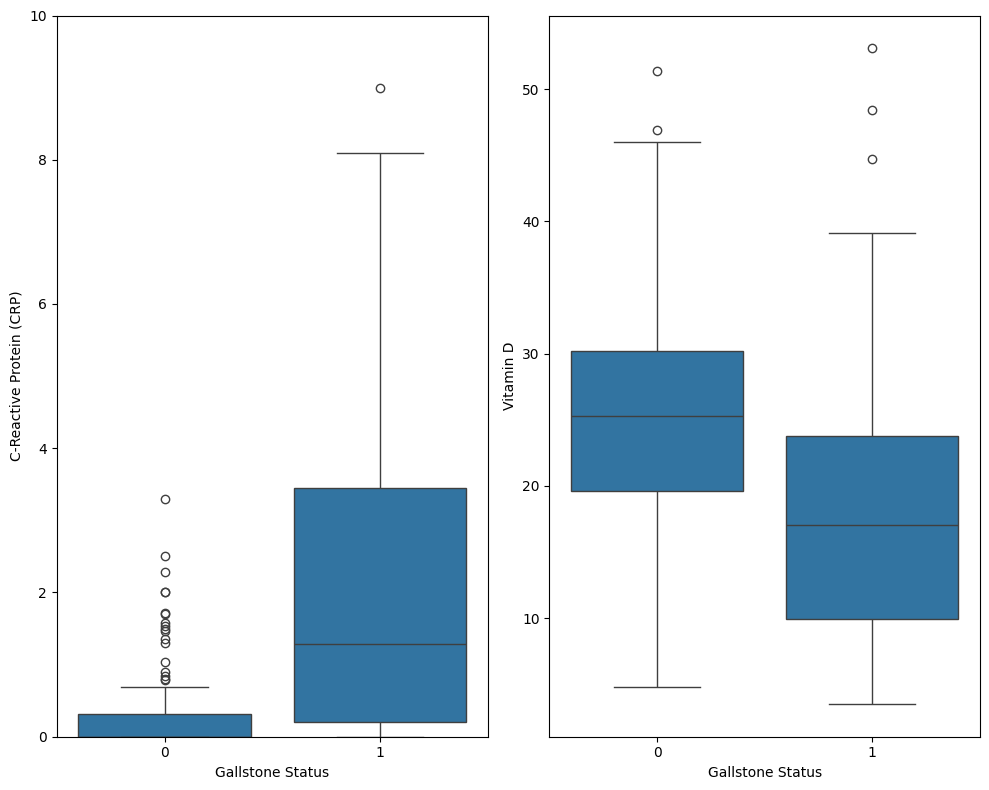

In [31]:
vit_col = [col for col in df.columns if 'Vit' in col or 'vit' in col][0]
fig, axes = plt.subplots(1, 2, figsize=(10,8))

sns.boxplot(data=df, x="Gallstone Status", y= "C-Reactive Protein (CRP)", ax=axes[0])
sns.boxplot(data=df, x='Gallstone Status', y = vit_col, ax=axes[1])
axes[0].set_ylim(0, 10)

plt.tight_layout()

As shown in the two boxplots, there are clear differences between the two groups. Patients with gallstone disease (0) tend to have lower CRP levels and higher vitamin D levels than healthy people.